kmeans

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [3]:
from pathlib import Path
import sys

current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

src_path = str(project_root / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from feature_engineering import create_customer_features

In [4]:
print(create_customer_features)

<function create_customer_features at 0x000001DB94637D70>


In [5]:
df = pd.read_csv(
    project_root / "data" / "bank_transaction_cleaned.csv"
)

print("Cleaned Dataset Shape:", df.shape)

display(df.head())

Cleaned Dataset Shape: (987516, 9)


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
0,T1,C5841053,1994-01-10,F,JAMSHEDPUR,17819.05,2016-08-02,14:32:07,25.0
1,T2,C2142763,1957-04-04,M,JHAJJAR,2270.69,2016-08-02,14:18:58,27999.0
2,T3,C4417068,1996-11-26,F,MUMBAI,17874.44,2016-08-02,14:27:12,459.0
3,T4,C5342380,1973-09-14,F,MUMBAI,866503.21,2016-08-02,14:27:14,2060.0
4,T5,C9031234,1988-03-24,F,NAVI MUMBAI,6714.43,2016-08-02,18:11:56,1762.5


In [6]:
customer_features = create_customer_features(df)

print("Customer-level Dataset Shape:", customer_features.shape)

display(customer_features.head())

Customer-level Dataset Shape: (840651, 9)


,CustomerID,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
0,C1010011,28.5,2553.0,2553.0,2,3107.027197,5106.0,76340.635,2
1,C1010012,22.0,1499.0,1499.0,1,0.000000,1499.0,24204.490,1
2,C1010014,28.0,727.5,727.5,2,675.286976,1455.0,100112.950,2
3,C1010018,26.0,30.0,30.0,1,0.000000,30.0,496.180,1
4,C1010024,51.0,5000.0,5000.0,1,0.000000,5000.0,87058.650,1


In [7]:
print("Dataset Information:")
customer_features.info()

print("\nMissing Values:")
display(customer_features.isnull().sum())

print("\nStatistical Summary:")
display(customer_features.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 840651 entries, 0 to 840650
Data columns (total 9 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   CustomerID               840651 non-null  str    
 1   CustomerAge              839227 non-null  float64
 2   AvgTransactionAmount     840651 non-null  float64
 3   MedianTransactionAmount  840651 non-null  float64
 4   TransactionFrequency     840651 non-null  int64  
 5   TransactionStd           840651 non-null  float64
 6   TotalTransactionAmount   840651 non-null  float64
 7   AccountBalance           840651 non-null  float64
 8   ActiveDays               840651 non-null  int64  
dtypes: float64(6), int64(2), str(1)
memory usage: 57.7 MB

Missing Values:


CustomerID                    0
CustomerAge                1424
AvgTransactionAmount          0
MedianTransactionAmount       0
TransactionFrequency          0
TransactionStd                0
TotalTransactionAmount        0
AccountBalance                0
ActiveDays                    0
dtype: int64


Statistical Summary:


,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
count,839227.000000,8.406510e+05,8.406510e+05,840651.000000,840651.000000,8.406510e+05,8.406510e+05,840651.000000
mean,30.842815,1.454566e+03,1.440385e+03,1.174704,239.071519,1.707623e+03,1.043317e+05,1.170796
std,8.349556,6.047530e+03,6.032405e+03,0.435715,2124.560092,6.696405e+03,7.837663e+05,0.429401
min,18.000000,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000e+00,0.000000e+00,1.000000
25%,25.000000,1.800000e+02,1.780000e+02,1.000000,0.000000,1.980000e+02,5.247640e+03,1.000000
50%,29.000000,4.750000e+02,4.650000e+02,1.000000,0.000000,5.000000e+02,1.728527e+04,1.000000
75%,34.000000,1.176000e+03,1.155000e+03,1.000000,0.000000,1.420000e+03,5.596091e+04,1.000000
max,86.000000,1.560035e+06,1.560035e+06,6.000000,511784.089233,1.560035e+06,1.150355e+08,6.000000


In [8]:
customer_features['CustomerAge'].isnull().sum()

np.int64(1424)

In [9]:
customer_features = create_customer_features(df)

In [ ]:
customer_features.dropna(subset=['CustomerAge'],inplace=True)

In [11]:
print("Missing values:")
print(customer_features.isnull().sum())

print("Remaining customers:", len(customer_features))

Missing values:
CustomerID                 0
CustomerAge                0
AvgTransactionAmount       0
MedianTransactionAmount    0
TransactionFrequency       0
TransactionStd             0
TotalTransactionAmount     0
AccountBalance             0
ActiveDays                 0
dtype: int64
Remaining customers: 839227


In [12]:
features = [
    'CustomerAge',
    'AvgTransactionAmount',
    'MedianTransactionAmount',
    'TransactionFrequency',
    'TransactionStd',
    'TotalTransactionAmount',
    'AccountBalance',
    'ActiveDays'
]

X = customer_features[features].copy()

display(X.head())

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
0,28.5,2553.0,2553.0,2,3107.027197,5106.0,76340.635,2
1,22.0,1499.0,1499.0,1,0.000000,1499.0,24204.490,1
2,28.0,727.5,727.5,2,675.286976,1455.0,100112.950,2
3,26.0,30.0,30.0,1,0.000000,30.0,496.180,1
4,51.0,5000.0,5000.0,1,0.000000,5000.0,87058.650,1


In [13]:
# Checking data types
print(X.dtypes)

# Check missing values
print("\nMissing values:")
print(X.isnull().sum())

# Check infinite values
print("\nInfinite values:")
print(np.isinf(X).sum())

# Check dataset dimensions
print("\nDataset shape:", X.shape)

# Statistical summary
display(X.describe())

CustomerAge                float64
AvgTransactionAmount       float64
MedianTransactionAmount    float64
TransactionFrequency         int64
TransactionStd             float64
TotalTransactionAmount     float64
AccountBalance             float64
ActiveDays                   int64
dtype: object

Missing values:
CustomerAge                0
AvgTransactionAmount       0
MedianTransactionAmount    0
TransactionFrequency       0
TransactionStd             0
TotalTransactionAmount     0
AccountBalance             0
ActiveDays                 0
dtype: int64

Infinite values:
CustomerAge                0
AvgTransactionAmount       0
MedianTransactionAmount    0
TransactionFrequency       0
TransactionStd             0
TotalTransactionAmount     0
AccountBalance             0
ActiveDays                 0
dtype: int64

Dataset shape: (839227, 8)


,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
count,839227.000000,8.392270e+05,8.392270e+05,839227.000000,839227.000000,8.392270e+05,8.392270e+05,839227.000000
mean,30.842815,1.453970e+03,1.439764e+03,1.174997,239.476636,1.707454e+03,1.043642e+05,1.171082
std,8.349556,6.047975e+03,6.032823e+03,0.436022,2126.338991,6.697869e+03,7.842569e+05,0.429704
min,18.000000,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000e+00,0.000000e+00,1.000000
25%,25.000000,1.800000e+02,1.780000e+02,1.000000,0.000000,1.980000e+02,5.259380e+03,1.000000
50%,29.000000,4.750000e+02,4.650000e+02,1.000000,0.000000,5.000000e+02,1.730383e+04,1.000000
75%,34.000000,1.176000e+03,1.155000e+03,1.000000,0.000000,1.420000e+03,5.601785e+04,1.000000
max,86.000000,1.560035e+06,1.560035e+06,6.000000,511784.089233,1.560035e+06,1.150355e+08,6.000000


In [14]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = (
    (X < lower_bound) | (X > upper_bound)
).sum()

outlier_percentage = (outlier_counts / len(X)) * 100

outlier_summary = pd.DataFrame({
    'Outlier_Count': outlier_counts,
    'Outlier_Percentage': outlier_percentage.round(2)
})

display(outlier_summary)

,Outlier_Count,Outlier_Percentage
CustomerAge,40740,4.85
AvgTransactionAmount,87213,10.39
MedianTransactionAmount,87673,10.45
TransactionFrequency,129393,15.42
TransactionStd,128670,15.33
TotalTransactionAmount,85771,10.22
AccountBalance,109848,13.09
ActiveDays,127114,15.15


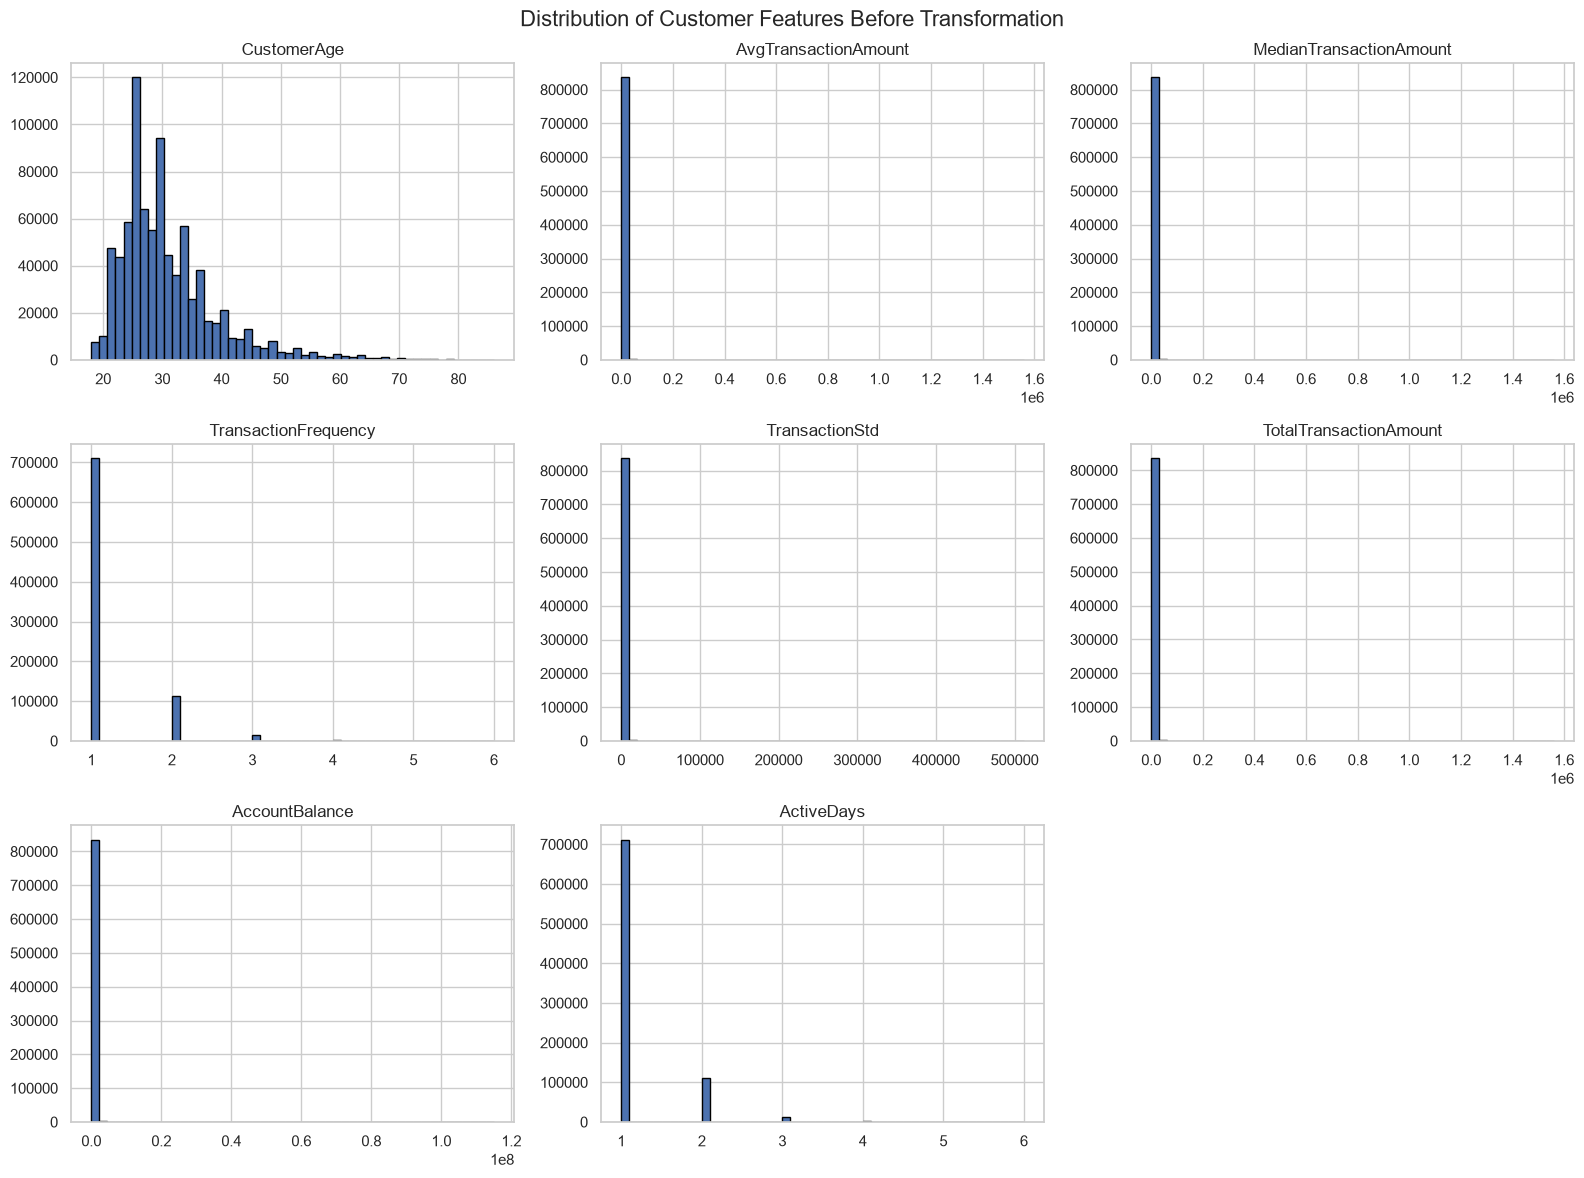

In [15]:
import matplotlib.pyplot as plt

X.hist(
    bins=50,
    figsize=(16, 12),
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Customer Features Before Transformation',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [16]:
X_transformed = X.copy()

skewed_features = [
    'AvgTransactionAmount',
    'MedianTransactionAmount',
    'TransactionFrequency',
    'TransactionStd',
    'TotalTransactionAmount',
    'AccountBalance',
    'ActiveDays'
]

for col in skewed_features:

    X_transformed[col] = (
        np.sign(X_transformed[col]) *
        np.log1p(np.abs(X_transformed[col]))
    )

display(X_transformed.head())

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
0,28.5,7.845416,7.845416,1.098612,8.041743,8.538367,11.242974,1.098612
1,22.0,7.313220,7.313220,0.693147,0.000000,7.313220,10.094335,0.693147
2,28.0,6.590988,6.590988,1.098612,6.516618,7.283448,11.514064,1.098612
3,26.0,3.433987,3.433987,0.693147,0.000000,3.433987,6.208952,0.693147
4,51.0,8.517393,8.517393,0.693147,0.000000,8.517393,11.374349,0.693147


applying transformation to improve the highly skewed data

In [17]:
skewness_comparison = pd.DataFrame({
    'Before_Transformation': X.skew(),
    'After_Transformation': X_transformed.skew()
})

display(skewness_comparison)

,Before_Transformation,After_Transformation
CustomerAge,1.769883,1.769883
AvgTransactionAmount,63.903843,-0.184732
MedianTransactionAmount,64.338254,-0.177522
TransactionFrequency,2.658079,2.265196
TransactionStd,49.456292,2.211205
TotalTransactionAmount,51.969058,-0.204903
AccountBalance,69.169224,-1.078602
ActiveDays,2.664201,2.283952


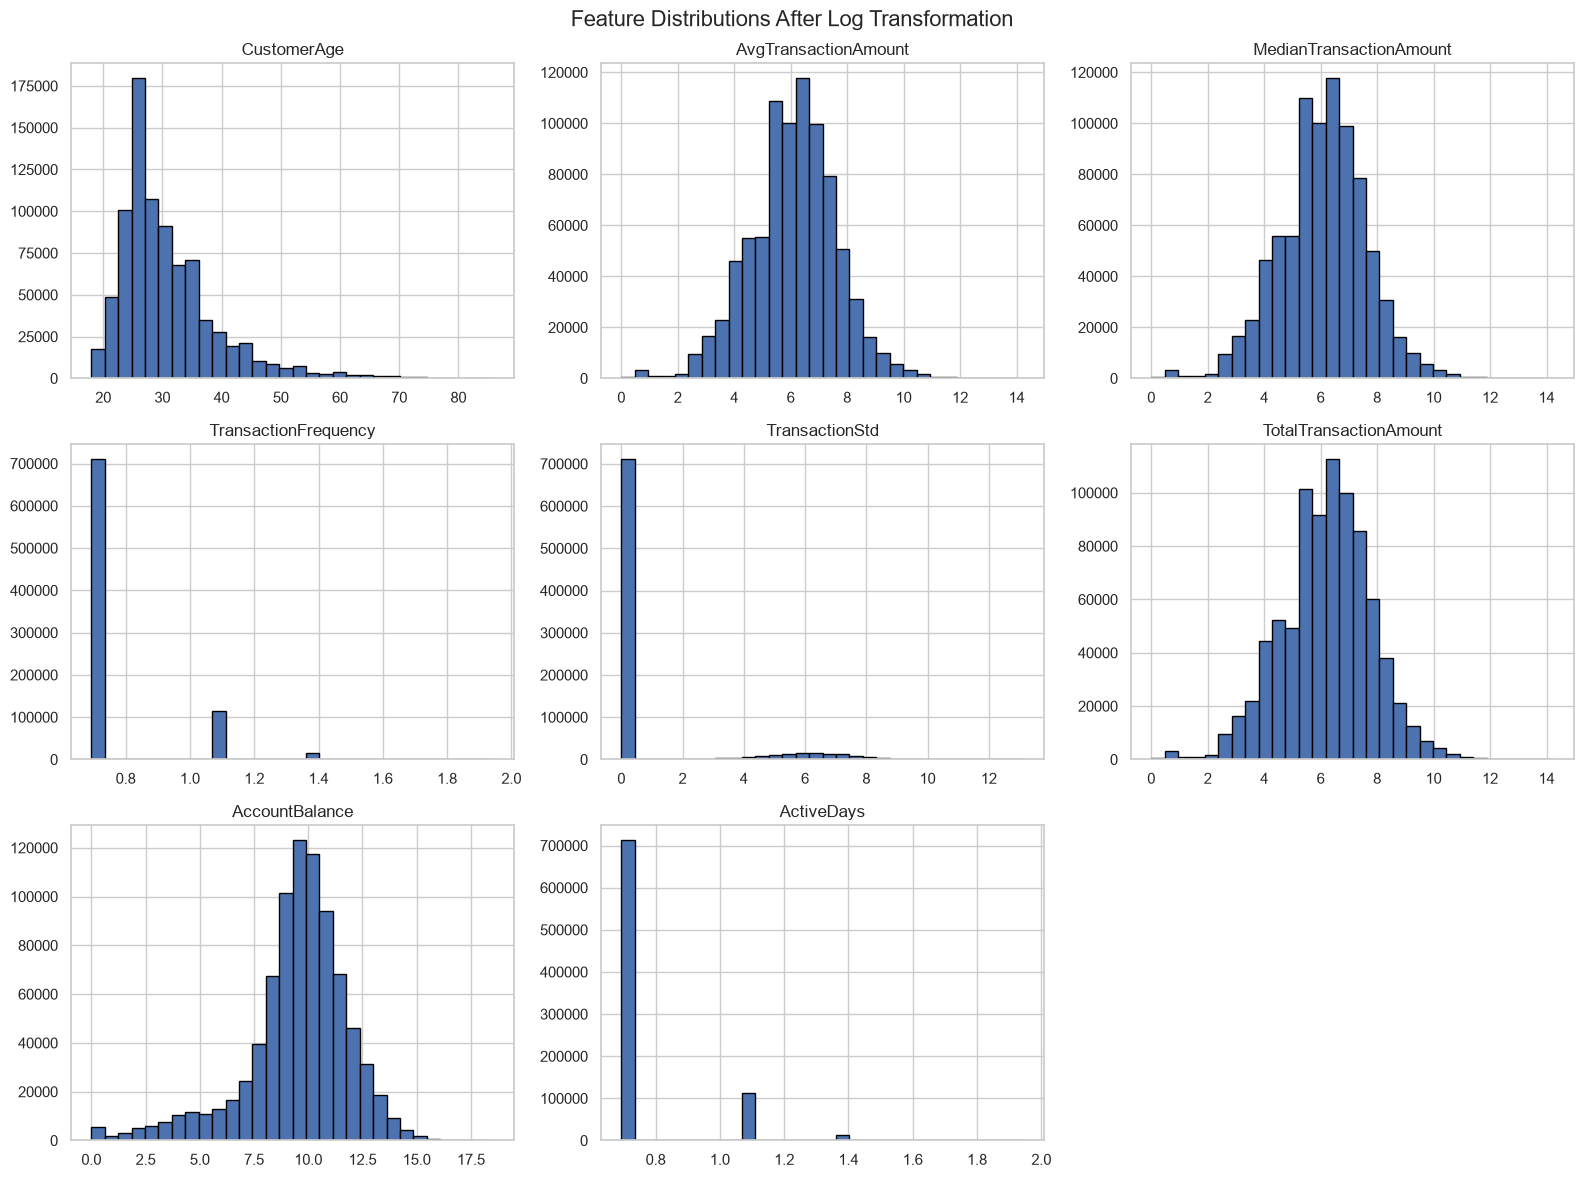

In [18]:
X_transformed.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    "Feature Distributions After Log Transformation",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_transformed)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

display(X_scaled.head())

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
0,-0.280592,1.148158,1.157040,2.038874,3.115721,1.471994,0.727242,2.071998
1,-1.059077,0.802439,0.810853,-0.413559,-0.409317,0.703142,0.250622,-0.409749
2,-0.340475,0.333272,0.341049,2.038874,2.447194,0.684458,0.839729,2.071998
3,-0.580009,-1.717539,-1.712542,-0.413559,-0.409317,-1.731306,-1.361591,-0.409749
4,2.414164,1.584679,1.594153,-0.413559,-0.409317,1.458831,0.781755,-0.409749


verifying scaling

In [20]:
print("Feature means:")
display(X_scaled.mean().round(3))

print("\nFeature standard deviations:")
display(X_scaled.std().round(3))

Feature means:


CustomerAge               -0.0
AvgTransactionAmount      -0.0
MedianTransactionAmount    0.0
TransactionFrequency      -0.0
TransactionStd            -0.0
TotalTransactionAmount    -0.0
AccountBalance            -0.0
ActiveDays                -0.0
dtype: float64


Feature standard deviations:


CustomerAge                1.0
AvgTransactionAmount       1.0
MedianTransactionAmount    1.0
TransactionFrequency       1.0
TransactionStd             1.0
TotalTransactionAmount     1.0
AccountBalance             1.0
ActiveDays                 1.0
dtype: float64

using the elbow and the silhouette method for finding the optimal number of clusters 

In [21]:
#elbow method
from sklearn.cluster import KMeans

inertia_values = []

max_k = min(10, len(X_scaled) - 1)
k_values = range(2, max_k + 1)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

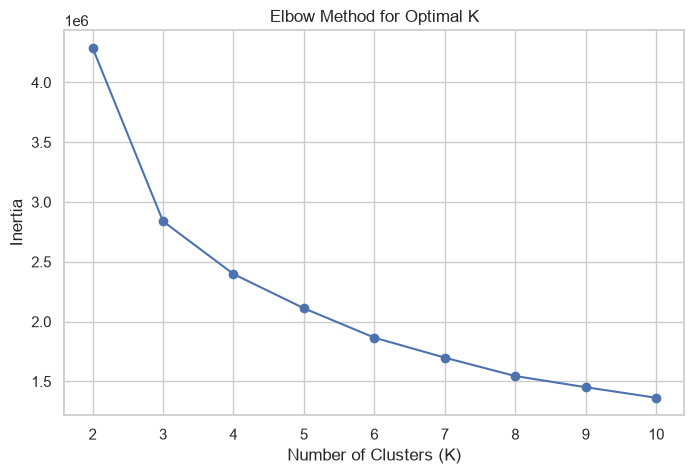

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')

plt.xticks(list(k_values))
plt.grid(True)
plt.show()

silhouette score

In [23]:
from sklearn.metrics import silhouette_score

silhouette_values = []

sample_size = min(10000, len(X_scaled))

for k in range(2, max_k + 1):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=sample_size,
        random_state=42
    )

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4925
K = 3, Silhouette Score = 0.3618
K = 4, Silhouette Score = 0.3081
K = 5, Silhouette Score = 0.3122
K = 6, Silhouette Score = 0.3275
K = 7, Silhouette Score = 0.2961
K = 8, Silhouette Score = 0.2663
K = 9, Silhouette Score = 0.2699
K = 10, Silhouette Score = 0.2782


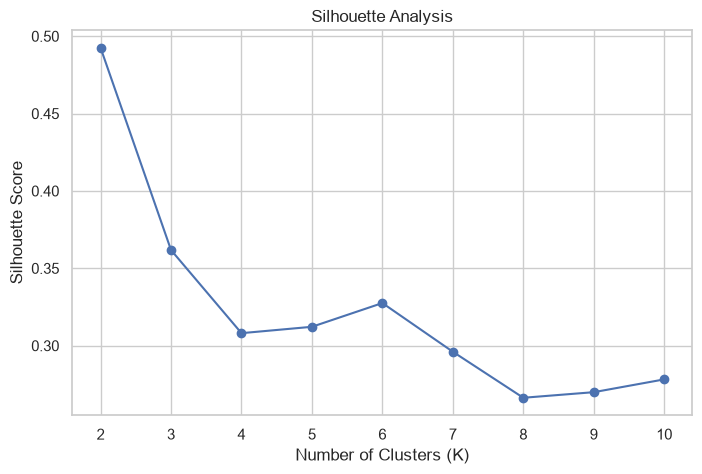

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, max_k + 1),
    silhouette_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')

plt.xticks(range(2, max_k + 1))
plt.grid(True)
plt.show()

In [25]:
optimal_k = 3  

print("Selected number of clusters:", optimal_k)

Selected number of clusters: 3


In [26]:
kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

customer_features['KMeans_Cluster'] = kmeans_labels

In [29]:
display(
    customer_features[
        ['CustomerID', 'KMeans_Cluster']
    ].head(10)
)

,CustomerID,KMeans_Cluster
0,C1010011,1
1,C1010012,0
2,C1010014,1
3,C1010018,2
4,C1010024,0
5,C1010028,0
6,C1010031,1
7,C1010035,1
8,C1010036,2
9,C1010037,0


In [30]:
cluster_counts = customer_features[
    'KMeans_Cluster'
].value_counts().sort_index()

print(cluster_counts)

KMeans_Cluster
0    372380
1    128276
2    338571
Name: count, dtype: int64


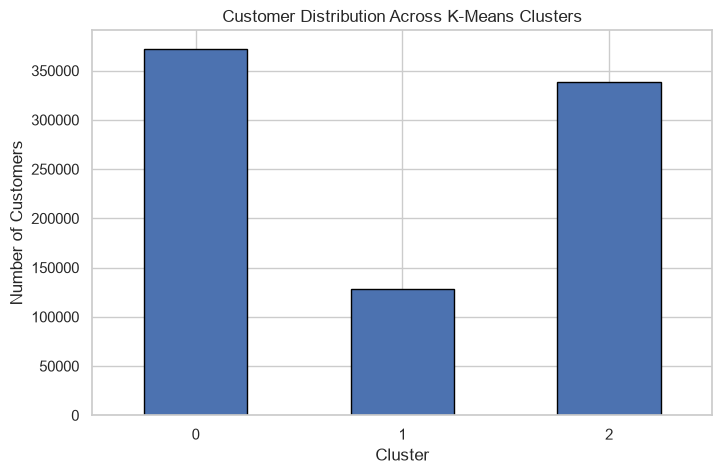

In [31]:
plt.figure(figsize=(8, 5))

cluster_counts.plot(
    kind='bar',
    edgecolor='black'
)

plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.title('Customer Distribution Across K-Means Clusters')

plt.xticks(rotation=0)
plt.show()

evaluating

In [33]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

baseline_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels,
    sample_size=min(10000, len(X_scaled)),
    random_state=42
)

baseline_db = davies_bouldin_score(
    X_scaled,
    kmeans_labels
)

baseline_ch = calinski_harabasz_score(
    X_scaled,
    kmeans_labels
)

print("Baseline K-Means Evaluation")
print("Silhouette Score:", round(baseline_silhouette, 4))
print("Davies-Bouldin Index:", round(baseline_db, 4))
print("Calinski-Harabasz Score:", round(baseline_ch, 4))

Baseline K-Means Evaluation
Silhouette Score: 0.3618
Davies-Bouldin Index: 0.9762
Calinski-Harabasz Score: 572836.5882


In [38]:
baseline_metrics = {
    'Silhouette Score': baseline_silhouette,
    'Davies-Bouldin Index': baseline_db,
    'Calinski-Harabasz Score': baseline_ch
}

print(baseline_metrics)

{'Silhouette Score': 0.3617908928769214, 'Davies-Bouldin Index': 0.9761722183806798, 'Calinski-Harabasz Score': 572836.5881885783}


PCA to reduce 8 features to two dimensions for plottting

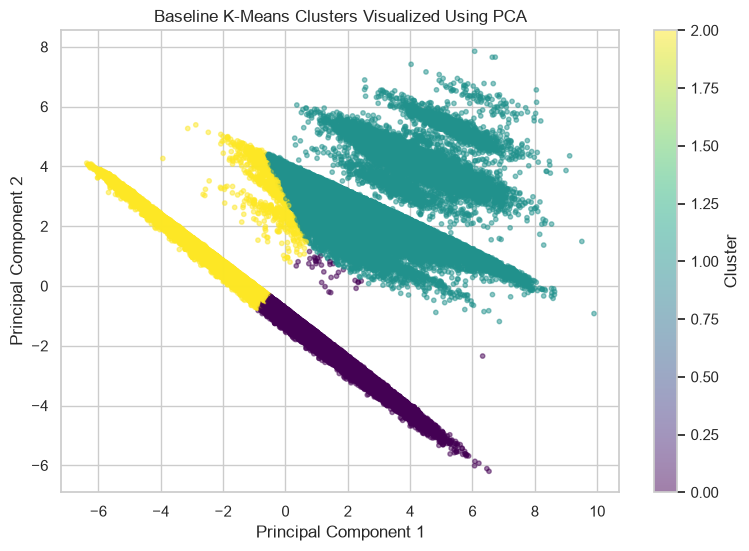

In [34]:
from sklearn.decomposition import PCA

pca_visualization = PCA(n_components=2)

X_pca_visualization = pca_visualization.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca_visualization[:, 0],
    X_pca_visualization[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=10,
    alpha=0.5
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Baseline K-Means Clusters Visualized Using PCA')

plt.colorbar(label='Cluster')
plt.show()

using original customers features for interpreting customer segments

cluster wise mean

In [35]:
cluster_profiles = customer_features.groupby(
    'KMeans_Cluster'
)[features].mean()

display(cluster_profiles.round(2))

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
KMeans_Cluster,,,,,,,,
0,33.42,2623.30,2623.30,1.00,0.00,2623.63,160794.61,1.00
1,30.74,1457.44,1364.50,2.14,1566.60,3114.43,99233.17,2.11
2,28.05,166.56,166.56,1.00,0.05,166.72,44242.88,1.00


cluster wise medians

In [36]:
cluster_medians = customer_features.groupby(
    'KMeans_Cluster'
)[features].median()

display(cluster_medians.round(2))

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
KMeans_Cluster,,,,,,,,
0,31.0,1053.0,1053.0,1.0,0.00,1053.00,28282.75,1.0
1,29.5,638.0,594.5,2.0,470.23,1355.42,24785.64,2.0
2,27.0,147.0,147.0,1.0,0.00,147.00,9025.74,1.0


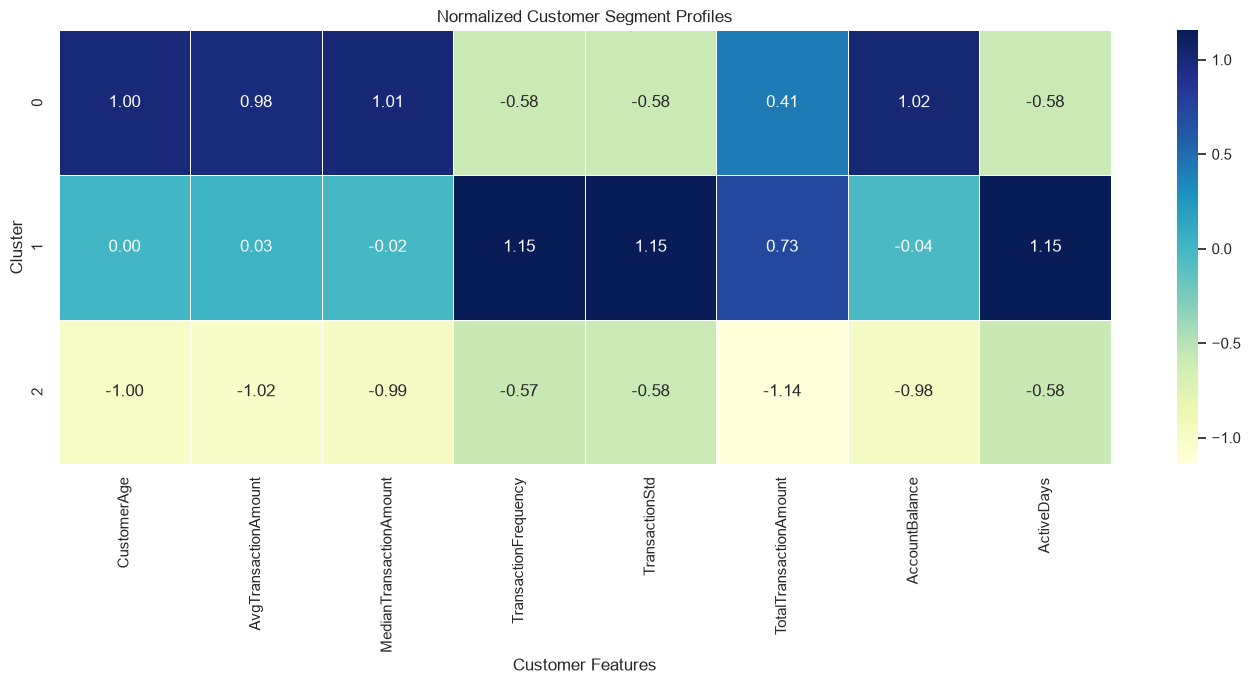

In [39]:
import seaborn as sns

# Normalize cluster profiles feature-wise for visualization
cluster_profiles_normalized = (
    cluster_profiles - cluster_profiles.mean()
) / cluster_profiles.std()

plt.figure(figsize=(14, 7))

sns.heatmap(
    cluster_profiles_normalized,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f',
    linewidths=0.5
)

plt.xlabel('Customer Features')
plt.ylabel('Cluster')
plt.title('Normalized Customer Segment Profiles')

plt.tight_layout()
plt.show()

checking with PCA to see whether reducing number of features will improve clustering

In [40]:
from sklearn.decomposition import PCA

In [41]:
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Number of PCA components:", X_pca.shape[1])

print(
    "Total explained variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Original number of features: 8
Number of PCA components: 4
Total explained variance: 98.76 %


In [42]:
explained_variance_df = pd.DataFrame({
    'Principal Component': [
        f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))
    ],
    'Explained Variance Ratio': pca.explained_variance_ratio_,
    'Explained Variance (%)': (
        pca.explained_variance_ratio_ * 100
    )
})

display(explained_variance_df.round(4))

,Principal Component,Explained Variance Ratio,Explained Variance (%)
0,PC1,0.4508,45.0756
1,PC2,0.3120,31.1971
2,PC3,0.1300,12.9950
3,PC4,0.0949,9.4928


visualizing cumulative explained variance

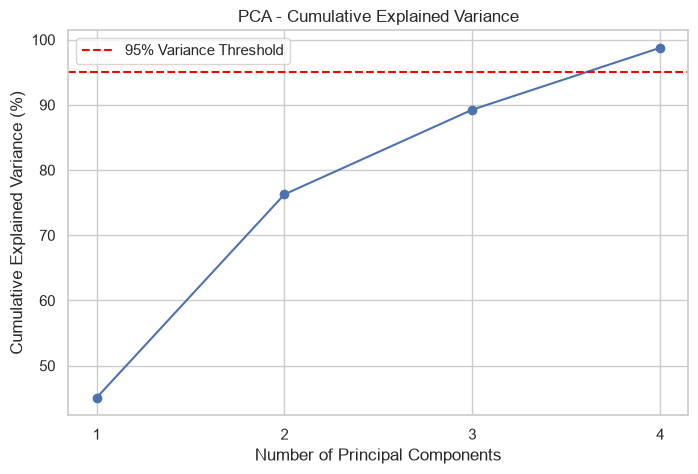

In [43]:
explained_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance * 100,
    marker='o'
)

plt.axhline(
    y=95,
    color='red',
    linestyle='--',
    label='95% Variance Threshold'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('PCA - Cumulative Explained Variance')

plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.grid(True)
plt.show()

Finding the optimal K for PCA-based K-Means

In [44]:
pca_inertia_values = []

pca_k_values = range(2, 11)

for k in pca_k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_pca)

    pca_inertia_values.append(kmeans.inertia_)

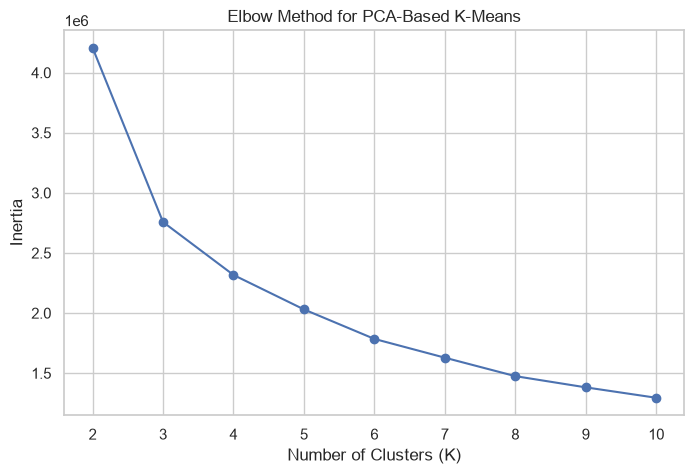

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(pca_k_values),
    pca_inertia_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for PCA-Based K-Means')

plt.xticks(list(pca_k_values))
plt.grid(True)
plt.show()

In [46]:
#silhouette
pca_silhouette_values = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca)

    score = silhouette_score(
        X_pca,
        labels,
        sample_size=10000,
        random_state=42
    )

    pca_silhouette_values.append(score)

    print(
        f"K = {k}, Silhouette Score = {score:.4f}"
    )

K = 2, Silhouette Score = 0.4933
K = 3, Silhouette Score = 0.3667
K = 4, Silhouette Score = 0.3131
K = 5, Silhouette Score = 0.3173
K = 6, Silhouette Score = 0.3313
K = 7, Silhouette Score = 0.2989
K = 8, Silhouette Score = 0.2689
K = 9, Silhouette Score = 0.2730
K = 10, Silhouette Score = 0.2743


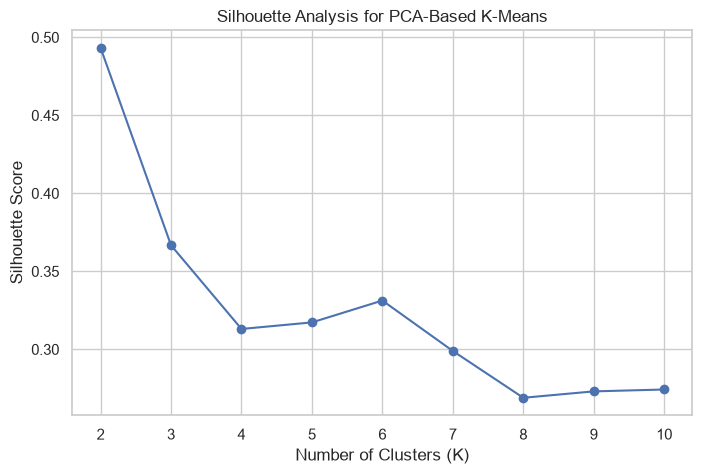

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    pca_silhouette_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis for PCA-Based K-Means')

plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

checking pca based kmeans for both k=2 and k=3 

In [48]:
pca_kmeans_results = {}

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_pca)

    pca_kmeans_results[k] = labels

    customer_features[f'PCA_KMeans_K{k}'] = labels

    print(f"\nResults for K = {k}")
    print(customer_features[f'PCA_KMeans_K{k}'].value_counts().sort_index())


Results for K = 2
PCA_KMeans_K2
0    710160
1    129067
Name: count, dtype: int64

Results for K = 3
PCA_KMeans_K3
0    375848
1    128264
2    335115
Name: count, dtype: int64


Using X_scaled instead of X_pca here because original K-Means model was evaluated using X_scaled. Evaluating both PCA cluster assignments in that same feature space makes the comparison more consistent.

In [49]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

pca_evaluation_results = []

for k in [2, 3]:

    labels = pca_kmeans_results[k]

    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=10000,
        random_state=42
    )

    db_index = davies_bouldin_score(X_scaled, labels)

    ch_score = calinski_harabasz_score(X_scaled, labels)

    pca_evaluation_results.append({
        'K': k,
        'Silhouette Score': silhouette,
        'Davies-Bouldin Index': db_index,
        'Calinski-Harabasz Score': ch_score
    })

pca_evaluation_df = pd.DataFrame(pca_evaluation_results)

display(pca_evaluation_df.round(4))

,K,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,0.4925,0.8091,474155.4736
1,3,0.3619,0.9758,572832.6391


In [50]:
#PCA-based K-Means model
pca_optimal_k = 3

pca_kmeans_model = KMeans(
    n_clusters=pca_optimal_k,
    random_state=42,
    n_init=10
)

pca_cluster_labels = pca_kmeans_model.fit_predict(X_pca)

customer_features['PCA_KMeans_Cluster'] = pca_cluster_labels

In [51]:
pca_cluster_counts = (
    customer_features['PCA_KMeans_Cluster']
    .value_counts()
    .sort_index()
)

pca_cluster_percentages = (
    customer_features['PCA_KMeans_Cluster']
    .value_counts(normalize=True)
    .sort_index() * 100
)

cluster_distribution = pd.DataFrame({
    'Customer Count': pca_cluster_counts,
    'Percentage': pca_cluster_percentages
})

display(cluster_distribution.round(2))

,Customer Count,Percentage
PCA_KMeans_Cluster,,
0,375848,44.79
1,128264,15.28
2,335115,39.93


In [52]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

final_silhouette = silhouette_score(
    X_scaled,
    pca_cluster_labels,
    sample_size=10000,
    random_state=42
)

final_db = davies_bouldin_score(
    X_scaled,
    pca_cluster_labels
)

final_ch = calinski_harabasz_score(
    X_scaled,
    pca_cluster_labels
)

print("PCA K-Means Evaluation")
print("----------------------")
print("Silhouette Score:", round(final_silhouette, 4))
print("Davies-Bouldin Index:", round(final_db, 4))
print("Calinski-Harabasz Score:", round(final_ch, 4))

PCA K-Means Evaluation
----------------------
Silhouette Score: 0.3619
Davies-Bouldin Index: 0.9758
Calinski-Harabasz Score: 572832.6391


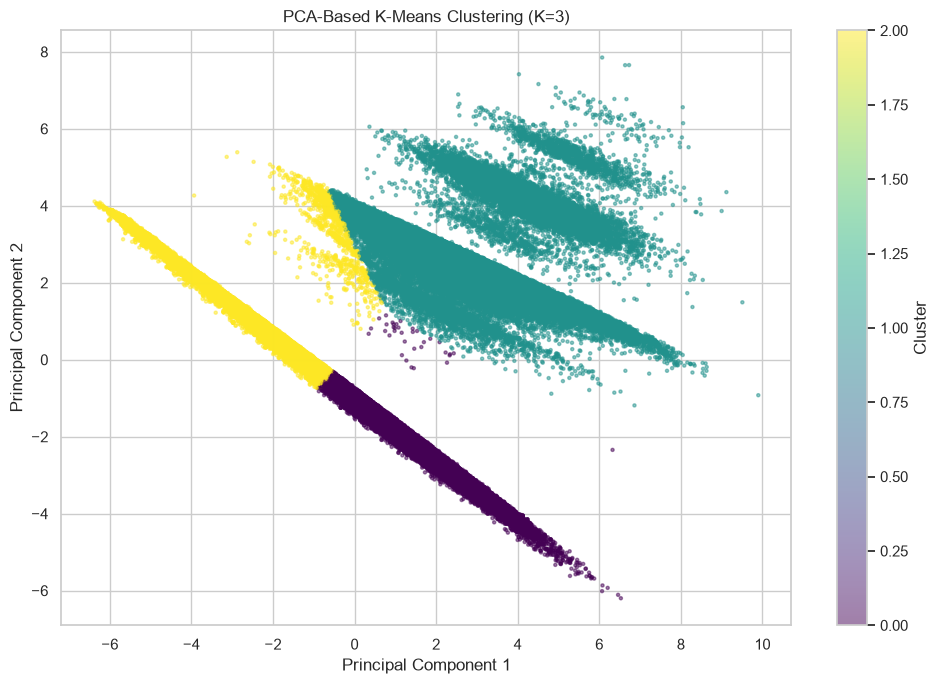

In [53]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pca_cluster_labels,
    cmap='viridis',
    s=5,
    alpha=0.5
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA-Based K-Means Clustering (K=3)')
plt.colorbar(label='Cluster')
plt.tight_layout()
plt.show()

understanding the clusters

In [54]:
pca_cluster_profiles = customer_features.groupby(
    'PCA_KMeans_Cluster'
)[features].mean()

display(pca_cluster_profiles.round(2))

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
PCA_KMeans_Cluster,,,,,,,,
0,33.39,2602.77,2602.77,1.00,0.00,2603.11,160000.94,1.00
1,30.74,1457.56,1364.62,2.14,1566.74,3114.69,99241.38,2.11
2,28.03,164.15,164.15,1.00,0.05,164.32,43925.70,1.00


In [55]:
pca_cluster_medians = customer_features.groupby(
    'PCA_KMeans_Cluster'
)[features].median()

display(pca_cluster_medians.round(2))

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
PCA_KMeans_Cluster,,,,,,,,
0,31.0,1040.95,1040.95,1.0,0.00,1041.0,28102.51,1.0
1,29.5,638.00,594.52,2.0,470.24,1356.0,24788.06,2.0
2,27.0,145.00,145.00,1.0,0.00,145.0,8969.11,1.0


Mean shows the average behaviour of customers.
Median shows the middle customer value and is less affected by extreme transaction values.

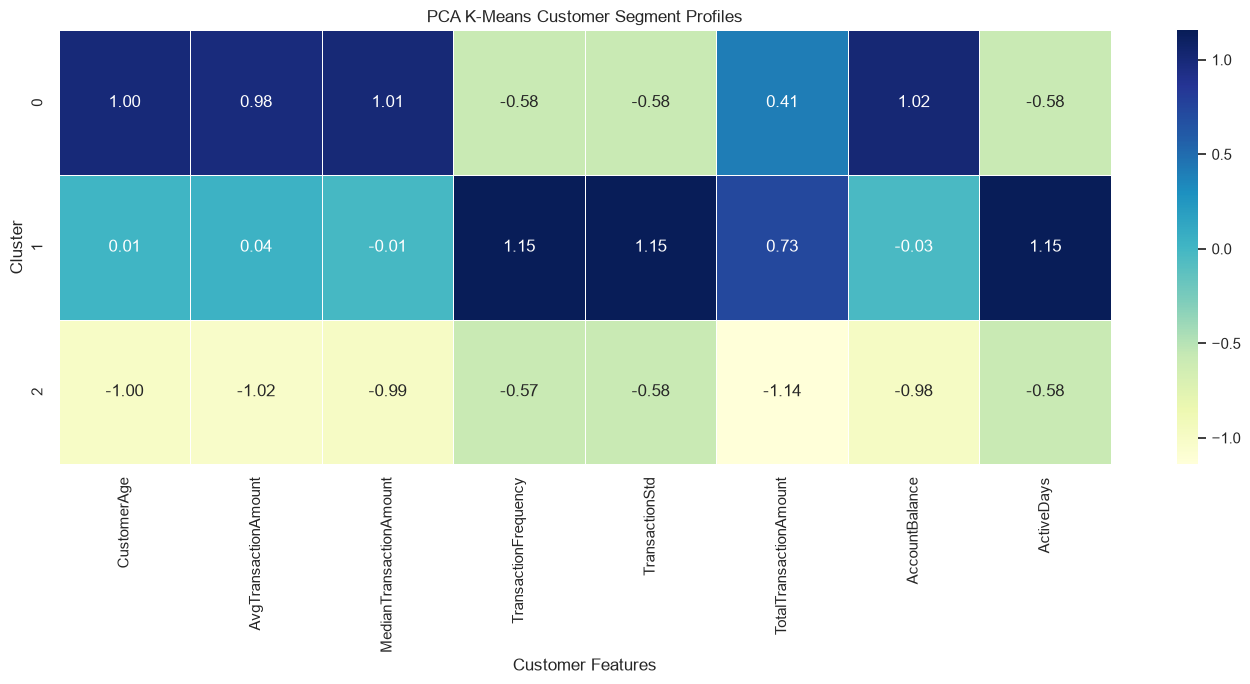

In [56]:
import seaborn as sns

normalized_profiles = (
    pca_cluster_profiles - pca_cluster_profiles.mean()
) / pca_cluster_profiles.std()

plt.figure(figsize=(14, 7))

sns.heatmap(
    normalized_profiles,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f',
    linewidths=0.5
)

plt.title('PCA K-Means Customer Segment Profiles')
plt.xlabel('Customer Features')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

cluster 0 - high value transactions but lesser frequency
cluster 1 - frequent and active transactors (has high transaction frequency)
cluster 2 - lower value transactions, less active frequency (transactors)

Comparing original K-Means and PCA K-Means

In [57]:
comparison_df = pd.DataFrame({
    'Model': [
        'Original K-Means (K=3)',
        'PCA K-Means (K=3)'
    ],
    'Silhouette Score': [
        baseline_silhouette,
        final_silhouette
    ],
    'Davies-Bouldin Index': [
        baseline_db,
        final_db
    ],
    'Calinski-Harabasz Score': [
        baseline_ch,
        final_ch
    ]
})

display(comparison_df.round(4))

,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,Original K-Means (K=3),0.3618,0.9762,572836.5882
1,PCA K-Means (K=3),0.3619,0.9758,572832.6391


In [58]:
cluster_comparison = pd.crosstab(
    customer_features['KMeans_Cluster'],
    customer_features['PCA_KMeans_Cluster'],
    normalize='index'
) * 100

display(cluster_comparison.round(2))

PCA_KMeans_Cluster,0,1,2
KMeans_Cluster,,,
0,100.00,0.00,0.00
1,0.00,99.99,0.01
2,1.02,0.00,98.98


The K-Means algorithm was applied to segment bank customers using eight customer-level behavioural and demographic features. The original model used three clusters. PCA was subsequently applied to reduce the feature space from eight dimensions to four while retaining approximately 98.76% of the explained variance.

A second K-Means model was trained using the PCA-transformed data with three clusters. The PCA-based model achieved evaluation scores very close to those of the original model, suggesting that dimensionality reduction preserved the overall clustering quality while reducing the number of input dimensions.

In [59]:
output_path = project_root / "data" / "kmeans_clustered_customers.csv"

customer_features.to_csv(output_path, index=False)

print("Final customer-level dataset saved successfully!")
print("Saved at:", output_path)

Final customer-level dataset saved successfully!
Saved at: c:\Users\ASUS\Desktop\ml project\bank_customer_segmentation\data\kmeans_clustered_customers.csv


In [60]:
saved_df = pd.read_csv(output_path)

print("Dataset shape:", saved_df.shape)
print("Columns:", saved_df.columns.tolist())
print(saved_df.head())

Dataset shape: (839227, 13)
Columns: ['CustomerID', 'CustomerAge', 'AvgTransactionAmount', 'MedianTransactionAmount', 'TransactionFrequency', 'TransactionStd', 'TotalTransactionAmount', 'AccountBalance', 'ActiveDays', 'KMeans_Cluster', 'PCA_KMeans_K2', 'PCA_KMeans_K3', 'PCA_KMeans_Cluster']
  CustomerID  CustomerAge  AvgTransactionAmount  MedianTransactionAmount  \
0   C1010011         28.5                2553.0                   2553.0   
1   C1010012         22.0                1499.0                   1499.0   
2   C1010014         28.0                 727.5                    727.5   
3   C1010018         26.0                  30.0                     30.0   
4   C1010024         51.0                5000.0                   5000.0   

   TransactionFrequency  TransactionStd  TotalTransactionAmount  \
0                     2     3107.027197                  5106.0   
1                     1        0.000000                  1499.0   
2                     2      675.286976           